        # Lesson 8.4 · Training Well
        ### Optimisers, learning rates and schedules, dropout, batch normalisation, regularisation, early stopping

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lessons 8.2 – 8.3 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Explain how **SGD, momentum, RMSprop, Adam/AdamW** differ and pick sensible defaults
- Find a good **learning rate** (range test) and apply **learning-rate schedules**
- Diagnose **over- and under-fitting** from learning curves
- Apply **weight decay, dropout, batch normalisation, early stopping**: and measure which actually help

> 🌾 **The story so far.** In Lesson 8.3 our MLP hit its best validation score at epoch 11 and then got *worse* while its training error kept falling. That gap is the central drama of deep learning. Today we learn to close it.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Optimisers: smarter ways to walk downhill

Plain gradient descent uses only the *current* slope. Cleverer optimisers use *history*.

| Optimiser | Idea | Update sketch | Use when |
|---|---|---|---|
| **SGD** | step against the gradient | $\theta \mathrel{-}= \eta g$ | simple baseline |
| **SGD + momentum** | keep a *velocity*: a rolling ball builds speed in consistent directions, damps zig-zags | $v \leftarrow \mu v + g;\ \theta \mathrel{-}= \eta v$ | CNNs with a good schedule |
| **RMSprop** | divide each parameter's step by a running average of its recent gradient *magnitude* | $\theta \mathrel{-}= \eta\, g/\sqrt{s+\epsilon}$ | recurrent nets |
| **Adam** | momentum **and** per-parameter scaling (+ bias correction) | $\theta \mathrel{-}= \eta\,\hat m/(\sqrt{\hat s}+\epsilon)$ | **the default**: works out of the box, `lr=1e-3` |
| **AdamW** | Adam with *decoupled* weight decay | | **modern default** (esp. Transformers) |

Watch them race down a narrow valley, steep in one direction and shallow in the other (like real loss surfaces):
$f(x,y)=0.1x^2+2y^2$.

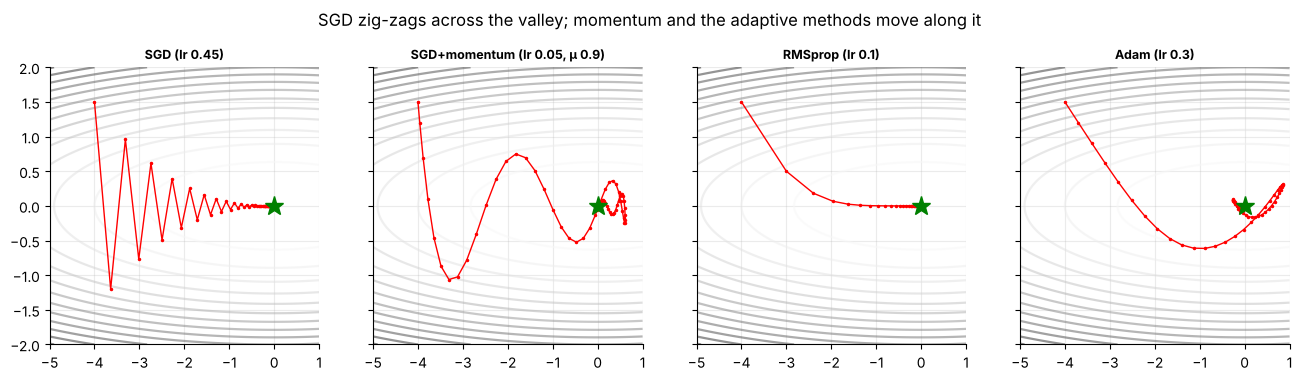

In [2]:
def run_opt(make_opt, steps=60, start=(-4.0, 1.5)):
    p = torch.tensor(start, requires_grad=True)
    opt = make_opt([p]); path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad(); loss = 0.1 * p[0] ** 2 + 2 * p[1] ** 2; loss.backward(); opt.step(); path.append(p.detach().clone().numpy())
    return np.array(path)

opts = {
    "SGD (lr 0.45)": lambda ps: torch.optim.SGD(ps, lr=0.45),
    "SGD+momentum (lr 0.05, μ 0.9)": lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9),
    "RMSprop (lr 0.1)": lambda ps: torch.optim.RMSprop(ps, lr=0.1),
    "Adam (lr 0.3)": lambda ps: torch.optim.Adam(ps, lr=0.3),
}
gx, gy = np.meshgrid(np.linspace(-5, 1, 200), np.linspace(-2, 2, 200))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, mk) in zip(axes, opts.items()):
    path = run_opt(mk)
    ax.contour(gx, gy, 0.1 * gx**2 + 2 * gy**2, levels=15, cmap="Greys", alpha=.5)
    ax.plot(path[:, 0], path[:, 1], "r.-", lw=1, ms=3); ax.plot(0, 0, "g*", ms=14); ax.set_title(name, fontsize=9)
plt.suptitle("SGD zig-zags across the valley; momentum and the adaptive methods move along it", y=1.04); plt.show()

**Rule of thumb:** start with **AdamW, `lr=1e-3`** and tune the *learning rate* first, everything else later.
For image classifiers trained for many epochs, **SGD + momentum 0.9 + a decaying schedule** often generalises slightly better, but needs more tuning.

---
### 🧩 Exercise 1: Momentum by hand  ⭐⭐

Implement SGD with momentum on $f(w)=w^2$ (gradient $2w$) yourself: `v = mu*v + grad; w = w - lr*v`, starting at `w=5`, `lr=0.1`, `mu=0.9`, 30 steps.
Store the list of `w` values (including the start, so 31 entries) in `my_path`. It must match PyTorch's `SGD(momentum=0.9)` exactly.

<details><summary>💡 Hint 1: gentle nudge</summary>

`w, v = 5.0, 0.0`; `my_path = [w]`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Each step: `g = 2 * w`; `v = mu * v + g`; `w = w - lr * v`; `my_path.append(w)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

PyTorch's convention is exactly this (velocity accumulates the raw gradient, then lr scales it).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
lr, mu = 0.1, 0.9
my_path = []

In [ ]:
try:
    p_ = torch.tensor(5.0, requires_grad=True); o_ = torch.optim.SGD([p_], lr=0.1, momentum=0.9); ref = [5.0]
    for _ in range(30):
        o_.zero_grad(); (p_ ** 2).backward(); o_.step(); ref.append(p_.item())
    ag.check("31 values", len(my_path) == 31)
    ag.check("identical to torch.optim.SGD(momentum=0.9)", len(my_path) == 31 and np.allclose(my_path, ref, atol=1e-5))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 2 · The learning rate: the dial that matters most

### Finding it: the LR range test (Leslie Smith)
Start with a tiny learning rate, **increase it exponentially** every mini-batch, record the loss. Pick a rate **just before** the loss starts to blow up
(often ~10× below the minimum of the curve).

We'll use the price-forecasting data from Lesson 8.3.

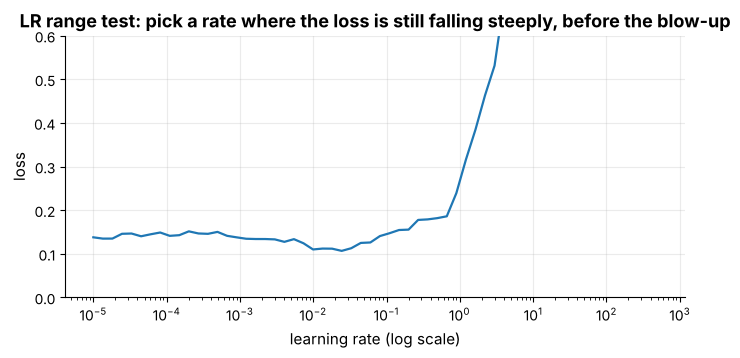

In [5]:
y_price = ag.price_series("tomato", "Central", "W")
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y_price.index).rolling(9, min_periods=1).sum()
tab = ag.make_origin_table(y_price, 4, pd.DataFrame({"rain_9w": rain9})).dropna()
feat_cols = [c for c in tab.columns if c != "target"]
n_tr, n_va = int(len(tab) * 0.65), int(len(tab) * 0.15)
tr, va, te = tab.iloc[:n_tr], tab.iloc[n_tr + 4:n_tr + n_va], tab.iloc[n_tr + n_va + 4:]
mu_, sd_ = tr[feat_cols].mean(), tr[feat_cols].std()
to_t = lambda d: (torch.tensor(((d[feat_cols] - mu_) / sd_).to_numpy(), dtype=torch.float32), torch.tensor(d["target"].to_numpy(), dtype=torch.float32))
(Xtr, ytr), (Xva, yva), (Xte, yte) = to_t(tr), to_t(va), to_t(te)

def make_mlp(hidden=128, p=0.0, bn=False, n_in=len(feat_cols)):
    layers = []
    for i, (a, b) in enumerate([(n_in, hidden), (hidden, hidden)]):
        layers += [nn.Linear(a, b)] + ([nn.BatchNorm1d(b)] if bn else []) + [nn.ReLU()] + ([nn.Dropout(p)] if p > 0 else [])
    return nn.Sequential(*layers, nn.Linear(hidden, 1), nn.Flatten(0))

# --- LR range test ---
torch.manual_seed(0)
m = make_mlp(); opt = torch.optim.SGD(m.parameters(), lr=1e-5, momentum=0.9)
lrs, losses, lr = [], [], 1e-5
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
for epoch in range(6):
    for xb, yb in loader:
        for g in opt.param_groups: g["lr"] = lr
        opt.zero_grad(); loss = nn.functional.l1_loss(m(xb), yb); loss.backward(); opt.step()
        lrs.append(lr); losses.append(loss.item()); lr *= 1.35
plt.figure(figsize=(8, 3.4)); plt.semilogx(lrs, pd.Series(losses).rolling(5, min_periods=1).mean()); plt.ylim(0, 0.6)
plt.xlabel("learning rate (log scale)"); plt.ylabel("loss"); plt.title("LR range test: pick a rate where the loss is still falling steeply, before the blow-up"); plt.show()

### Schedules: change the rate *during* training
Big steps early (explore), small steps late (settle in the valley). Common schedules:

| Scheduler | Behaviour |
|---|---|
| `StepLR(step_size, gamma)` | multiply lr by `gamma` every `step_size` epochs |
| `ExponentialLR(gamma)` | smooth exponential decay |
| `CosineAnnealingLR(T_max)` | half-cosine from `lr0` to ~0: a modern favourite |
| `ReduceLROnPlateau` | cut the lr when the *validation* metric stalls |
| `OneCycleLR` | warm up then anneal: fast convergence ("super-convergence") |
| **Warm-up** | start tiny, ramp up: essential for Transformers |

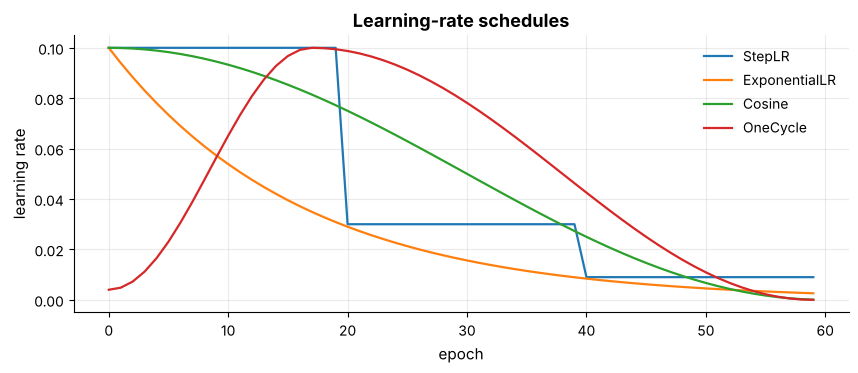

In [6]:
def lr_trace(make_sched, epochs=60, lr0=0.1):
    p = torch.nn.Parameter(torch.zeros(1)); opt = torch.optim.SGD([p], lr=lr0); sch = make_sched(opt); out = []
    for _ in range(epochs):
        out.append(opt.param_groups[0]["lr"]); opt.step(); sch.step()
    return out

plt.figure(figsize=(10, 3.6))
plt.plot(lr_trace(lambda o: torch.optim.lr_scheduler.StepLR(o, 20, 0.3)), label="StepLR")
plt.plot(lr_trace(lambda o: torch.optim.lr_scheduler.ExponentialLR(o, 0.94)), label="ExponentialLR")
plt.plot(lr_trace(lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, 60)), label="Cosine")
plt.plot(lr_trace(lambda o: torch.optim.lr_scheduler.OneCycleLR(o, max_lr=0.1, total_steps=60)), label="OneCycle")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.legend(); plt.title("Learning-rate schedules"); plt.show()

---
### 🧩 Exercise 2: Cosine annealing from the formula  ⭐⭐

The cosine schedule is $\eta_e = \eta_{\min} + \tfrac12(\eta_0-\eta_{\min})\bigl(1+\cos(\pi e/T)\bigr)$.
Write `cosine_lr(e, T, lr0, lr_min=0.0)` and compute `my_lrs = [cosine_lr(e, 50, 0.1) for e in range(50)]`.
It must equal what PyTorch's `CosineAnnealingLR(T_max=50)` produces.

<details><summary>💡 Hint 1: gentle nudge</summary>

`import math` is available as `np.pi` and `np.cos`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`return lr_min + 0.5 * (lr0 - lr_min) * (1 + np.cos(np.pi * e / T))`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

At e=0 you should get `lr0`; at e=T you'd reach `lr_min`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def cosine_lr(e, T, lr0, lr_min=0.0):
    return None

my_lrs = []

In [ ]:
try:
    ref = lr_trace(lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, 50), epochs=50, lr0=0.1)
    ag.check("50 values", len(my_lrs) == 50)
    ag.check("matches PyTorch's CosineAnnealingLR", len(my_lrs) == 50 and np.allclose(my_lrs, ref, atol=1e-8))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · Overfitting: when memorising beats learning

Our dataset has ~300 training rows; a 128-unit MLP has ~20,000 parameters. It can *memorise* the training set. Watch the learning curves:

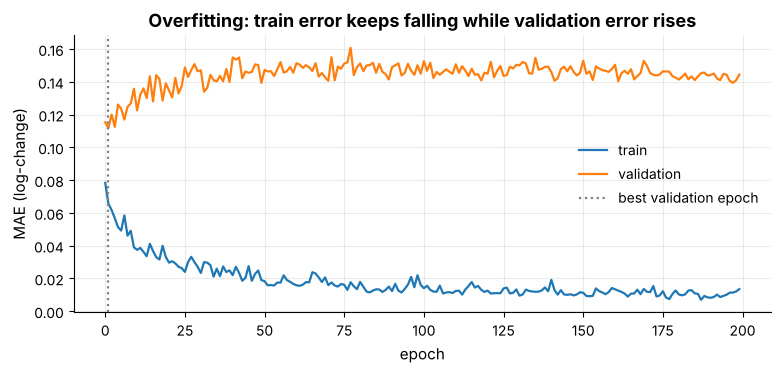

unregularised MLP -> final train 0.014, final val 0.144, TEST 0.101


In [9]:
class EarlyStopping:
    def __init__(self, patience=15, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_state, self.best_epoch, self.wait, self.epoch = np.inf, None, -1, 0, -1
    def step(self, val_loss, model):
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.best_epoch, self.wait = val_loss, self.epoch, 0
            self.best_state = {k: v.clone() for k, v in model.state_dict().items()}
            return False
        self.wait += 1
        return self.wait >= self.patience

def fit(model, epochs=200, lr=1e-3, wd=0.0, batch=32, patience=None, sched=None, seed=0):
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = {"cosine": lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)}.get(sched, lambda: None)()
    stopper = EarlyStopping(patience) if patience else None
    hist = []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); nn.functional.l1_loss(model(xb), yb).backward(); opt.step()
        if scheduler: scheduler.step()
        model.eval()
        with torch.no_grad():
            tl, vl = nn.functional.l1_loss(model(Xtr), ytr).item(), nn.functional.l1_loss(model(Xva), yva).item()
        hist.append((tl, vl))
        if stopper and stopper.step(vl, model): break
    if stopper: model.load_state_dict(stopper.best_state)           # restore the best weights
    model.eval()
    with torch.no_grad():
        test_mae = nn.functional.l1_loss(model(Xte), yte).item()
    return np.array(hist), test_mae

torch.manual_seed(0)
h0, test0 = fit(make_mlp())
plt.figure(figsize=(9, 3.6)); plt.plot(h0[:, 0], label="train"); plt.plot(h0[:, 1], label="validation")
plt.axvline(h0[:, 1].argmin(), color="gray", ls=":", label="best validation epoch"); plt.legend(); plt.xlabel("epoch"); plt.ylabel("MAE (log-change)")
plt.title("Overfitting: train error keeps falling while validation error rises"); plt.show()
print(f"unregularised MLP -> final train {h0[-1,0]:.3f}, final val {h0[-1,1]:.3f}, TEST {test0:.3f}")

| Curve pattern | Diagnosis | Remedies |
|---|---|---|
| train high, val high, close together | **underfitting** (high bias) | bigger model, more epochs, better features, lower regularisation |
| train low, val high (gap) | **overfitting** (high variance) | more data, regularise, smaller model, early stopping, augmentation |
| both low, close | 🎉 | ship it (after a final test-set check) |

## 4 · The regularisation toolbox

**Weight decay (L2)**: penalise large weights: $\mathcal L' = \mathcal L + \lambda\sum w^2$. Keeps the function smooth. In `AdamW`, pass `weight_decay=`.

**Dropout**: during training, randomly zero each activation with probability *p*. The network can't rely on any single neuron, so it learns redundant, robust features (like training an ensemble of thinned networks).
*Inverted dropout* scales the survivors by $1/(1-p)$ during training so that **at test time nothing changes**: `model.eval()` switches dropout off.

**Batch normalisation**: re-centre and re-scale each layer's inputs per mini-batch, then learn a scale & shift. Makes training faster and more stable, allows larger learning rates, and slightly regularises (batch noise).
Uses **batch statistics in train mode, running averages in eval mode**: forgetting `model.eval()` is a classic bug.

**Early stopping**: monitor validation loss; stop after *patience* epochs without improvement; **restore the best weights**.

**Others:** data augmentation (Lesson 8.6), smaller networks, ensembling, label smoothing.

---
### 🧩 Exercise 3: Dropout from scratch  ⭐⭐

Implement **inverted dropout**: `dropout_forward(x, p, training, rng)`.
- In training: zero each element with probability `p` and scale the survivors by `1/(1-p)`.
- In evaluation: return `x` unchanged.
Test on `x = np.ones(100_000)` with `p = 0.3`: store `out_train`, `out_eval`, the fraction of zeros `zero_frac`, and `mean_train`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`keep = rng.random(x.shape) >= p` is a boolean mask where `True` means *keep*.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`return x * keep / (1 - p)` when `training`; otherwise `return x`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

The mean of `out_train` should stay ≈ 1: that's why we scale survivors by 1/(1−p).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def dropout_forward(x, p, training, rng):
    return x

rng = np.random.default_rng(0)
x = np.ones(100_000)
out_train = out_eval = zero_frac = mean_train = None

In [ ]:
try:
    ag.check("about 30 % of units are dropped", zero_frac is not None and abs(zero_frac - 0.3) < 0.01)
    ag.check("the average activation is preserved (≈ 1)", mean_train is not None and abs(mean_train - 1) < 0.02, "scale survivors by 1/(1-p)")
    ag.check("evaluation mode is the identity", out_eval is not None and np.array_equal(out_eval, np.ones(100_000)))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
### 🧩 Exercise 4: An early-stopping callback  ⭐⭐

Complete the `EarlyStopping2` class below. `step(val_loss, model)` must: record the best loss/epoch and a **copy of the model's weights** when the loss improves by more than `min_delta`;
otherwise increment a wait counter; and **return `True` when `wait >= patience`**.
(The class from the lesson is a reference; try not to peek!)

<details><summary>💡 Hint 1: gentle nudge</summary>

Keep `self.best_loss = float('inf')`, `self.wait = 0`, `self.epoch = -1`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

On improvement: update `best_loss`, `best_epoch = self.epoch`, reset `wait = 0`, store `{k: v.clone() for k, v in model.state_dict().items()}`; `return False`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Otherwise: `self.wait += 1; return self.wait >= self.patience`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
class EarlyStopping2:
    def __init__(self, patience=3, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_state, self.best_epoch, self.wait, self.epoch = float("inf"), None, -1, 0, -1
    def step(self, val_loss, model):
        self.epoch += 1
        return False

stopper = EarlyStopping2(patience=3)
probe = nn.Linear(1, 1)
stopped_at = None

In [ ]:
try:
    ag.check("stopped after 3 non-improving epochs (epoch index 5)", stopped_at == 5)
    ag.check("best epoch is 2 with loss 0.7", stopper.best_epoch == 2 and np.isclose(stopper.best_loss, 0.7))
    ag.check("it saved the weights from the BEST epoch (weight = 2.0)", stopper.best_state is not None and float(stopper.best_state["weight"]) == 2.0)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 5 · Which regulariser actually helps? Measure it.
Same data, same architecture, same seed. Only the *training recipe* changes. We judge on the **test** block (never used for any choices; except we report it once per recipe, so treat gaps below ~0.005 as noise).

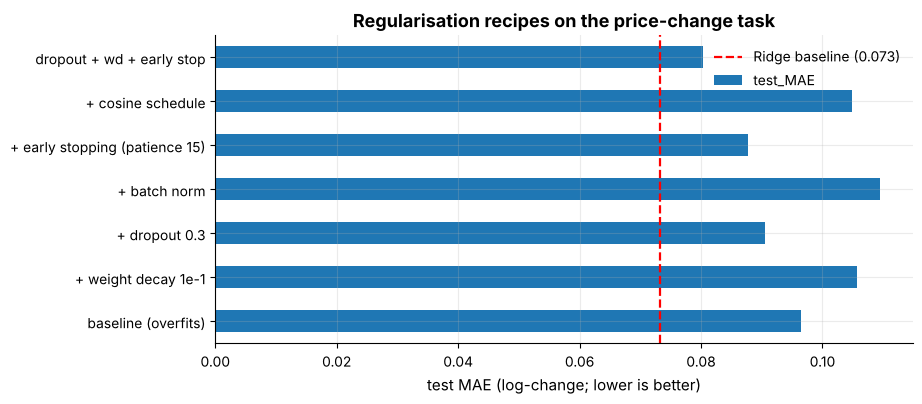

,epochs,best_val,test_MAE
baseline (overfits),200.0,0.1225,0.0965
+ weight decay 1e-1,200.0,0.1131,0.1057
+ dropout 0.3,200.0,0.1091,0.0905
+ batch norm,200.0,0.1477,0.1094
+ early stopping (patience 15),20.0,0.1121,0.0878
+ cosine schedule,200.0,0.0985,0.1048
dropout + wd + early stop,34.0,0.1093,0.0804


In [14]:
recipes = {
    "baseline (overfits)":            dict(model=lambda: make_mlp(),                  kw=dict()),
    "+ weight decay 1e-1":            dict(model=lambda: make_mlp(),                  kw=dict(wd=1e-1)),
    "+ dropout 0.3":                  dict(model=lambda: make_mlp(p=0.3),             kw=dict()),
    "+ batch norm":                   dict(model=lambda: make_mlp(bn=True),           kw=dict()),
    "+ early stopping (patience 15)": dict(model=lambda: make_mlp(),                  kw=dict(patience=15)),
    "+ cosine schedule":              dict(model=lambda: make_mlp(),                  kw=dict(sched="cosine")),
    "dropout + wd + early stop":      dict(model=lambda: make_mlp(p=0.3),             kw=dict(wd=1e-1, patience=15)),
}
rows = {}
for name, r in recipes.items():
    h, t = fit(r["model"](), **r["kw"])
    rows[name] = dict(epochs=len(h), best_val=h[:, 1].min(), test_MAE=t)
results = pd.DataFrame(rows).T.round(4)
from sklearn.linear_model import Ridge
ridge_mae = ag.mae(yte.numpy(), Ridge(10).fit(Xtr.numpy(), ytr.numpy()).predict(Xte.numpy()))
ax = results["test_MAE"].plot.barh(figsize=(9, 4), color="tab:blue"); ax.axvline(ridge_mae, color="red", ls="--", label=f"Ridge baseline ({ridge_mae:.3f})")
ax.set(xlabel="test MAE (log-change; lower is better)", title="Regularisation recipes on the price-change task"); ax.legend(); plt.show()
results

What to notice (re-run it: your exact decimals may differ):

- **Not every trick helps** every time. Batch-norm on ~300 samples with batches of 32 is noisy; a heavy weight decay can even hurt. Techniques are *hypotheses*: you test them.
- **Early stopping** is the cheapest and most reliable: it uses a tenth of the epochs and removes the worst of the overfitting.
- **Combining** mild regularisers (dropout + weight decay + early stopping) gave the best network.
- Even so, the best network still **trails or only matches the Ridge baseline** (red line) on this tiny, nearly linear problem. Complexity doesn't beat data and structure; it needs **more data** to shine (the next lessons use thousands of images).
- Differences smaller than ~0.005 are within noise with this little data: don't over-interpret a single run.

---
### 🧩 Exercise 5: Tune the dropout rate on validation data  ⭐⭐

For `p in [0.0, 0.1, 0.3, 0.5, 0.7]` train `make_mlp(p=p)` with `fit(..., patience=15)` and record the **best validation MAE** (`h[:, 1].min()`).
Store results in dict `val_by_p` and the winning rate in `best_p`. Remember: choose by **validation**, not test.

<details><summary>💡 Hint 1: gentle nudge</summary>

`h, test = fit(make_mlp(p=p), patience=15)`: `h` has columns (train, val) per epoch.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`val_by_p[p] = float(h[:, 1].min())`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`best_p = min(val_by_p, key=val_by_p.get)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
val_by_p = {}
best_p = None

In [ ]:
try:
    ag.check("five rates evaluated", set(val_by_p) == {0.0, 0.1, 0.3, 0.5, 0.7})
    ag.check("best_p is the arg-min of validation MAE", best_p == min(val_by_p, key=val_by_p.get))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 6 · A practical training recipe (print this)

1. **Baseline first** (mean, linear model). Know what "good" means.
2. Overfit **one small batch** deliberately: if the loss can't go to ~0, you have a bug.
3. Start with **AdamW, lr 1e-3**, a modest network; run the **LR range test**.
4. Plot **learning curves** (train & validation per epoch): always.
5. Add regularisation **in this order**: early stopping → weight decay → dropout → augmentation → smaller model / more data.
6. Use a **schedule** (cosine or one-cycle) for long runs.
7. Fix seeds, log settings, run **several seeds**; touch the **test set once**.

## 🎓 Mini-quiz
1. Why does inverted dropout scale activations by $1/(1-p)$?
2. Your validation loss is *lower* than training loss. Plausible causes?
3. Why choose hyper-parameters on the validation set, not the test set?

<details><summary>Answers</summary>

1. So the *expected* activation is unchanged between training and evaluation. 2. Dropout/augmentation active only in training; training loss averaged *during* the epoch while the weights improve; validation split easier/smaller. 3. Selecting on the test set leaks information, making the final score optimistic.
</details>

        ---
        ## 🧾 Recap
        - **Adam/AdamW** (lr 1e-3) is the safe default; **momentum** smooths zig-zags; the learning rate matters more than the optimiser.
- Find the lr with a **range test**; refine with **schedules** (cosine, one-cycle, plateau, warm-up).
- Read **learning curves** to diagnose under- vs over-fitting.
- Regularise with **early stopping, weight decay, dropout, batch-norm**: and *measure* each; on small data, simple baselines are formidable.

**Next up:** Lesson 8.5; Project 1: handwritten digit recognition with an ANN and then a CNN.